# **LIMPIEZA DE DATOS**

Carlos Francisco Montoya Urzua

23 de Marzo de 2026

1. Cargar el dataset




In [84]:
import pandas as pd
import numpy as np



In [109]:
df = pd.read_csv("ventaCSV.csv")
#Ver primeras filas:
df.head()

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,Mexico,100.0,"""10"""
1,2,Juan,NaN,mexico,200.0,"""20"""
2,3,Ana,25.0,Mexico,100.0,"""10"""
3,4,Luis,150.0,Guadalajara,300.0,"""30"""
4,5,Maria,30.0,MEXICO,NaN,NaN


2. Revisar estructura del dataset

Esto permite detectar:

•	tipos de datos incorrectos
•	valores faltantes
•	número de columnas





In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   id         11 non-null     int64  
 1   nombre     11 non-null     object 
 2   edad       9 non-null      float64
 3   ciudad     10 non-null     object 
 4   ventas     9 non-null      float64
 5   ganancias  9 non-null      object 
dtypes: float64(2), int64(1), object(3)
memory usage: 660.0+ bytes


In [87]:
#Dimensiones del dataset:
df.shape

(11, 6)

3. Eliminar duplicados
Los datasets muchas veces tienen registros repetidos.



In [88]:
#Ver duplicados:
print(df.duplicated().sum())


0


In [89]:
#Eliminar duplicados:
df = df.drop_duplicates()
df

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,Mexico,100.0,"""10"""
1,2,Juan,NaN,mexico,200.0,"""20"""
2,3,Ana,25.0,Mexico,100.0,"""10"""
3,4,Luis,150.0,Guadalajara,300.0,"""30"""
4,5,Maria,30.0,MEXICO,NaN,NaN
5,6,Luis,150.0,guadalajara,300.0,"""30"""
6,7,Rosa,NaN,colima,100000.0,"""10"""
7,8,Eduardo,20.0,monterrey,450.0,"""45"""
8,10,jorge,40.0,Colima,350.0,"""35"""
9,11,Norma,3.0,sayula,100.0,"""10"""


4. Detectar valores faltantes



In [90]:
print(df.isnull().sum())
#Porcentaje de valores faltantes:
print((df.isnull().sum()/len(df))*100)

id           0
nombre       0
edad         2
ciudad       1
ventas       2
ganancias    2
dtype: int64
id            0.000000
nombre        0.000000
edad         18.181818
ciudad        9.090909
ventas       18.181818
ganancias    18.181818
dtype: float64


5. Tratar valores faltantes
Hay varias estrategias.

Opción 1: Eliminar filas con NaN
df = df.dropna()

Opción 2: Eliminar columnas con muchos NaN
df = df.drop(columns=["columna"])

Opción 3: Rellenar con media
df["edad"].fillna(df["edad"].mean(), inplace=True)

Opción 4: Rellenar con mediana
df["edad"].fillna(df["edad"].median(), inplace=True)

Opción 5: Rellenar con categoría
df["ciudad"].fillna("Desconocido", inplace=True)


In [110]:
#Opción 5: Rellenar con categoría df["ciudad"].fillna("Desconocido", inplace=True)
df["ciudad"].fillna("Desconocido", inplace=True)

/tmp/ipykernel_1862/3527257606.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["ciudad"].fillna("Desconocido", inplace=True)


In [92]:
df

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,Mexico,100.0,"""10"""
1,2,Juan,NaN,mexico,200.0,"""20"""
2,3,Ana,25.0,Mexico,100.0,"""10"""
3,4,Luis,150.0,Guadalajara,300.0,"""30"""
4,5,Maria,30.0,MEXICO,NaN,NaN
5,6,Luis,150.0,guadalajara,300.0,"""30"""
6,7,Rosa,NaN,colima,100000.0,"""10"""
7,8,Eduardo,20.0,monterrey,450.0,"""45"""
8,10,jorge,40.0,Colima,350.0,"""35"""
9,11,Norma,3.0,sayula,100.0,"""10"""


In [111]:
#SE DECIDE QUE SI AMBAS COLUMNAS VENTAS Y GANANCIAS SON NaN, SE COLOCARA UN 0

#ES NECESARIO CORREGIR EL TIPO DE DATO EN GANANCIAS
df['ganancias'] = df['ganancias'].str.replace('"', '')
df['ganancias'].astype(np.number)

/usr/local/lib/python3.12/dist-packages/pandas/core/dtypes/common.py:1645: DeprecationWarning: Converting `np.inexact` or `np.floating` to a dtype is deprecated. The current result is `float64` which is not strictly correct.
  npdtype = np.dtype(dtype)


,ganancias
0,10.0
1,20.0
2,10.0
3,30.0
4,NaN
5,30.0
6,10.0
7,45.0
8,35.0
9,10.0


In [112]:
df['ventas'].fillna(0, inplace=True)
df['ganancias'].fillna(0, inplace=True)
df

/tmp/ipykernel_1862/3575279307.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['ventas'].fillna(0, inplace=True)
/tmp/ipykernel_1862/3575279307.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.me

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,Mexico,100.0,10
1,2,Juan,NaN,mexico,200.0,20
2,3,Ana,25.0,Mexico,100.0,10
3,4,Luis,150.0,Guadalajara,300.0,30
4,5,Maria,30.0,MEXICO,0.0,0
5,6,Luis,150.0,guadalajara,300.0,30
6,7,Rosa,NaN,colima,100000.0,10
7,8,Eduardo,20.0,monterrey,450.0,45
8,10,jorge,40.0,Colima,350.0,35
9,11,Norma,3.0,sayula,100.0,10


In [113]:
#Opción 3: Rellenar con media df["edad"].fillna(df["edad"].mean(), inplace=True)
df["edad"].fillna(df["edad"].mean(), inplace=True)

/tmp/ipykernel_1862/1984018013.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["edad"].fillna(df["edad"].mean(), inplace=True)


In [96]:
df

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,Mexico,100.0,10
1,2,Juan,53.0,mexico,200.0,20
2,3,Ana,25.0,Mexico,100.0,10
3,4,Luis,150.0,Guadalajara,300.0,30
4,5,Maria,30.0,MEXICO,0.0,0
5,6,Luis,150.0,guadalajara,300.0,30
6,7,Rosa,53.0,colima,100000.0,10
7,8,Eduardo,20.0,monterrey,450.0,45
8,10,jorge,40.0,Colima,350.0,35
9,11,Norma,3.0,sayula,100.0,10


In [114]:
#CORREGIR AQUELLOS QUE APARECEN CON EDAD MENOR A 18
df.loc[df['edad'] < 18, 'edad'] = 18
df

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,Mexico,100.0,10
1,2,Juan,53.0,mexico,200.0,20
2,3,Ana,25.0,Mexico,100.0,10
3,4,Luis,150.0,Guadalajara,300.0,30
4,5,Maria,30.0,MEXICO,0.0,0
5,6,Luis,150.0,guadalajara,300.0,30
6,7,Rosa,53.0,colima,100000.0,10
7,8,Eduardo,20.0,monterrey,450.0,45
8,10,jorge,40.0,Colima,350.0,35
9,11,Norma,18.0,sayula,100.0,10


In [115]:
#CORREGIR AQUELLOS QUE APARECEN CON EDAD MAYOR A 70
df.loc[df['edad'] > 70, 'edad'] = 70
df

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,Mexico,100.0,10
1,2,Juan,53.0,mexico,200.0,20
2,3,Ana,25.0,Mexico,100.0,10
3,4,Luis,70.0,Guadalajara,300.0,30
4,5,Maria,30.0,MEXICO,0.0,0
5,6,Luis,70.0,guadalajara,300.0,30
6,7,Rosa,53.0,colima,100000.0,10
7,8,Eduardo,20.0,monterrey,450.0,45
8,10,jorge,40.0,Colima,350.0,35
9,11,Norma,18.0,sayula,100.0,10


6. Corregir tipos de datos
Muchos datasets tienen tipos incorrectos.



In [116]:
#Ver tipos:
print(df.dtypes)





id             int64
nombre        object
edad         float64
ciudad        object
ventas       float64
ganancias     object
dtype: object


In [100]:
#Convertir a número:
#df["ganancias"] = df["ganancias"].astype(str).str.replace('"', '', regex=False)
df["ganancias"] = pd.to_numeric(df["ganancias"], errors='coerce')
df

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,Mexico,100.0,10
1,2,Juan,53.0,mexico,200.0,20
2,3,Ana,25.0,Mexico,100.0,10
3,4,Luis,70.0,Guadalajara,300.0,30
4,5,Maria,30.0,MEXICO,0.0,0
5,6,Luis,70.0,guadalajara,300.0,30
6,7,Rosa,53.0,colima,100000.0,10
7,8,Eduardo,20.0,monterrey,450.0,45
8,10,jorge,40.0,Colima,350.0,35
9,11,Norma,18.0,sayula,100.0,10


In [101]:
#Convertir a fecha:
#df["fecha"] = pd.to_datetime(df["fecha"])
#NO HAY FECHAS

In [117]:
#Convertir a categoría:
df["cudad"] = df["ciudad"].astype("category")
df

,id,nombre,edad,ciudad,ventas,ganancias,cudad
0,1,Ana,25.0,Mexico,100.0,10,Mexico
1,2,Juan,53.0,mexico,200.0,20,mexico
2,3,Ana,25.0,Mexico,100.0,10,Mexico
3,4,Luis,70.0,Guadalajara,300.0,30,Guadalajara
4,5,Maria,30.0,MEXICO,0.0,0,MEXICO
5,6,Luis,70.0,guadalajara,300.0,30,guadalajara
6,7,Rosa,53.0,colima,100000.0,10,colima
7,8,Eduardo,20.0,monterrey,450.0,45,monterrey
8,10,jorge,40.0,Colima,350.0,35,Colima
9,11,Norma,18.0,sayula,100.0,10,sayula


7. Estandarizar texto
Problema común:
Mexico
mexico
MEXICO
Solución:



In [118]:
df["ciudad"] = df["ciudad"].str.lower()
#Eliminar espacios:
df["ciudad"] = df["ciudad"].str.strip()
df

,id,nombre,edad,ciudad,ventas,ganancias,cudad
0,1,Ana,25.0,mexico,100.0,10,Mexico
1,2,Juan,53.0,mexico,200.0,20,mexico
2,3,Ana,25.0,mexico,100.0,10,Mexico
3,4,Luis,70.0,guadalajara,300.0,30,Guadalajara
4,5,Maria,30.0,mexico,0.0,0,MEXICO
5,6,Luis,70.0,guadalajara,300.0,30,guadalajara
6,7,Rosa,53.0,colima,100000.0,10,colima
7,8,Eduardo,20.0,monterrey,450.0,45,monterrey
8,10,jorge,40.0,colima,350.0,35,Colima
9,11,Norma,18.0,sayula,100.0,10,sayula


In [119]:
df = df.drop(columns=df.columns[-1])

In [120]:
df

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,mexico,100.0,10
1,2,Juan,53.0,mexico,200.0,20
2,3,Ana,25.0,mexico,100.0,10
3,4,Luis,70.0,guadalajara,300.0,30
4,5,Maria,30.0,mexico,0.0,0
5,6,Luis,70.0,guadalajara,300.0,30
6,7,Rosa,53.0,colima,100000.0,10
7,8,Eduardo,20.0,monterrey,450.0,45
8,10,jorge,40.0,colima,350.0,35
9,11,Norma,18.0,sayula,100.0,10


8. Corregir categorías inconsistentes

Ejemplo:
M
Male
Hombre
Solución:


In [83]:
df["genero"] = df["genero"].replace({
    "M":"Male",
    "Hombre":"Male"
})

#NO EXISTE GENERO

KeyError: 'genero'

9. Detectar outliers
Usando boxplot:



<Axes: xlabel='edad'>

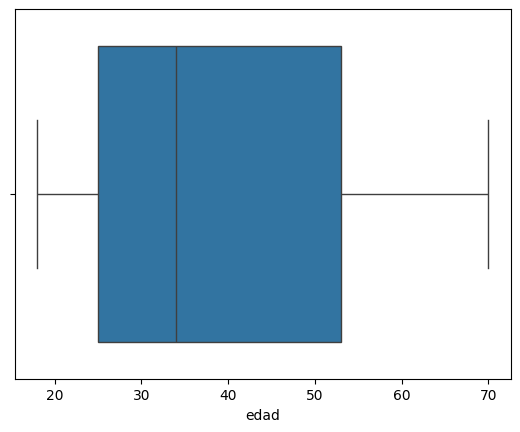

In [121]:
import seaborn as sns
sns.boxplot(x=df["edad"])

Eliminar outliers usando IQR
Q1 = df["salario"].quantile(0.25)
Q3 = df["salario"].quantile(0.75)
IQR = Q3 - Q1
df = df[(df["salario"] >= Q1 - 1.5*IQR) &
        (df["salario"] <= Q3 + 1.5*IQR)]


In [122]:
#Eliminar outliers usando IQR
Q1 = df["edad"].quantile(0.25)
Q3 = df["edad"].quantile(0.75)
IQR = Q3 - Q1
df = df[(df["edad"] >= Q1 - 1.5*IQR) &
        (df["edad"] <= Q3 + 1.5*IQR)]
df

,id,nombre,edad,ciudad,ventas,ganancias
0,1,Ana,25.0,mexico,100.0,10
1,2,Juan,53.0,mexico,200.0,20
2,3,Ana,25.0,mexico,100.0,10
3,4,Luis,70.0,guadalajara,300.0,30
4,5,Maria,30.0,mexico,0.0,0
5,6,Luis,70.0,guadalajara,300.0,30
6,7,Rosa,53.0,colima,100000.0,10
7,8,Eduardo,20.0,monterrey,450.0,45
8,10,jorge,40.0,colima,350.0,35
9,11,Norma,18.0,sayula,100.0,10


10. Eliminar columnas irrelevantes
Columnas que no aportan información:
•	ID
•	números aleatorios
•	códigos internos
Ejemplo:
df = df.drop(columns=["ID"])


In [123]:
df = df.drop(columns=["id"])

In [107]:
df

,nombre,edad,ciudad,ventas,ganancias,cudad
0,Ana,25.0,mexico,100.0,10,Mexico
1,Juan,53.0,mexico,200.0,20,mexico
2,Ana,25.0,mexico,100.0,10,Mexico
3,Luis,70.0,guadalajara,300.0,30,Guadalajara
4,Maria,30.0,mexico,0.0,0,MEXICO
5,Luis,70.0,guadalajara,300.0,30,guadalajara
6,Rosa,53.0,colima,100000.0,10,colima
7,Eduardo,20.0,monterrey,450.0,45,monterrey
8,jorge,40.0,colima,350.0,35,Colima
9,Norma,18.0,sayula,100.0,10,sayula


11. Renombrar columnas
Para mantener nombres claros.
df = df.rename(columns={
    "EdadPersona":"edad",
    "IngresoMensual":"ingreso"
})


In [124]:
df = df.rename(columns={ "edad":"EdadPersona", "ingreso":"IngresoMensual" })

In [125]:
df

,nombre,EdadPersona,ciudad,ventas,ganancias
0,Ana,25.0,mexico,100.0,10
1,Juan,53.0,mexico,200.0,20
2,Ana,25.0,mexico,100.0,10
3,Luis,70.0,guadalajara,300.0,30
4,Maria,30.0,mexico,0.0,0
5,Luis,70.0,guadalajara,300.0,30
6,Rosa,53.0,colima,100000.0,10
7,Eduardo,20.0,monterrey,450.0,45
8,jorge,40.0,colima,350.0,35
9,Norma,18.0,sayula,100.0,10


In [126]:
df = df.rename(columns={ "EdadPersona":"edad", "IngresoMensual":"ingreso" })

In [127]:
df

,nombre,edad,ciudad,ventas,ganancias
0,Ana,25.0,mexico,100.0,10
1,Juan,53.0,mexico,200.0,20
2,Ana,25.0,mexico,100.0,10
3,Luis,70.0,guadalajara,300.0,30
4,Maria,30.0,mexico,0.0,0
5,Luis,70.0,guadalajara,300.0,30
6,Rosa,53.0,colima,100000.0,10
7,Eduardo,20.0,monterrey,450.0,45
8,jorge,40.0,colima,350.0,35
9,Norma,18.0,sayula,100.0,10


12. Crear variables nuevas
Ejemplo:
df["ingreso_anual"] = df["ingreso_mensual"] * 12


In [128]:
df['ingreso_mensual'] = 20000
df["ingreso_anual"] = df["ingreso_mensual"] * 12

In [129]:
df

,nombre,edad,ciudad,ventas,ganancias,ingreso_mensual,ingreso_anual
0,Ana,25.0,mexico,100.0,10,20000,240000
1,Juan,53.0,mexico,200.0,20,20000,240000
2,Ana,25.0,mexico,100.0,10,20000,240000
3,Luis,70.0,guadalajara,300.0,30,20000,240000
4,Maria,30.0,mexico,0.0,0,20000,240000
5,Luis,70.0,guadalajara,300.0,30,20000,240000
6,Rosa,53.0,colima,100000.0,10,20000,240000
7,Eduardo,20.0,monterrey,450.0,45,20000,240000
8,jorge,40.0,colima,350.0,35,20000,240000
9,Norma,18.0,sayula,100.0,10,20000,240000


13. Verificar dataset limpio
Revisar nuevamente:



In [130]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   nombre           11 non-null     object 
 1   edad             11 non-null     float64
 2   ciudad           11 non-null     object 
 3   ventas           11 non-null     float64
 4   ganancias        11 non-null     object 
 5   ingreso_mensual  11 non-null     int64  
 6   ingreso_anual    11 non-null     int64  
dtypes: float64(2), int64(2), object(3)
memory usage: 748.0+ bytes


In [131]:
df.describe()



,edad,ventas,ingreso_mensual,ingreso_anual
count,11.000000,11.000000,11.0,11.0
mean,39.818182,9263.636364,20000.0,240000.0
std,18.993779,30094.202855,0.0,0.0
min,18.000000,0.000000,20000.0,240000.0
25%,25.000000,100.000000,20000.0,240000.0
50%,34.000000,200.000000,20000.0,240000.0
75%,53.000000,325.000000,20000.0,240000.0
max,70.000000,100000.000000,20000.0,240000.0


In [132]:
df.isnull().sum()

,0
nombre,0
edad,0
ciudad,0
ventas,0
ganancias,0
ingreso_mensual,0
ingreso_anual,0
